# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [1]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.13.0.3" 2026-10-24
OpenJDK Runtime Environment (build 21.0.13.0.3+1-1-24.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.13.0.3+1-1-24.04.1-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.13.0.3


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [2]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Overwriting Hello.java


In [3]:
!java Hello.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.13.0.3


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [4]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Overwriting TariffBefore.java


In [5]:
!java TariffBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [6]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Writing TariffAfter.java


In [7]:
!java TariffAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [8]:
!apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

PlantUML установлен


In [9]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


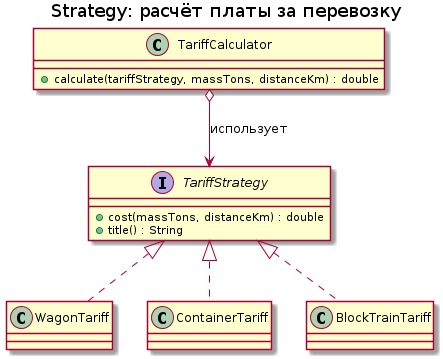

In [10]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

In [11]:
!apt-get update -qq
!apt-get install -y plantuml graphviz
!plantuml -version | head -3

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
plantuml is already the newest version (1:1.2020.2+ds-3ubuntu1.1).
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 45 not upgraded.
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
PlantUML version 1.2020.02 (Sun Mar 01 10:22:07 UTC 2020)


### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** в коде «до» меняется метод cost (добавляется ещё одна ветка else if). В коде «после» не меняется ни один существующий класс, добавляется только новый класс стратегии и одна строка в каталог.
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** legacyCost нужен как эталон поведения, чтобы тесты доказывали, что результат не изменился.
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** tariffCatalog.get(...) вернёт null, будет NullPointerException. Нужно проверять null и бросать понятное исключение (например, IllegalArgumentException("неизвестный вид отправки"))

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [12]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Overwriting FactoryBefore.java


In [13]:
!java FactoryBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [14]:
%%writefile FactoryAfter.java
// Factory Method: создание вагона без разбора типа условным оператором.
// Вариант 1: грузовая станция, фабрика создаёт тип вагона.
public class FactoryAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Вызывающий код работает только с типами WagonCreator и Wagon
        WagonCreator coveredWagonCreator = new CoveredWagonCreator();
        WagonCreator platformCreator = new PlatformCreator();
        WagonCreator tankWagonCreator = new TankWagonCreator();

        Wagon coveredWagon = coveredWagonCreator.createWagon(68);
        Wagon platform = platformCreator.createWagon(71);
        Wagon tankWagon = tankWagonCreator.createWagon(66);

        System.out.println("--- Вагоны, созданные фабричными методами ---");
        System.out.println(coveredWagon.description());
        System.out.println(platform.description());
        System.out.println(tankWagon.description());

        System.out.println();
        System.out.println("--- Проверки трёх исходных типов ---");
        check("описание крытого вагона не пустое и содержит грузоподъёмность",
                describesCapacity(coveredWagon, 68));
        check("описание платформы не пустое и содержит грузоподъёмность",
                describesCapacity(platform, 71));
        check("описание цистерны не пустое и содержит грузоподъёмность",
                describesCapacity(tankWagon, 66));
        check("CoveredWagonCreator создал именно CoveredWagon", coveredWagon instanceof CoveredWagon);
        check("PlatformCreator создал именно Platform", platform instanceof Platform);
        check("TankWagonCreator создал именно TankWagon", tankWagon instanceof TankWagon);
        check("описание через создателя совпадает с описанием самого вагона",
                coveredWagonCreator.prepareDescription(68).equals(coveredWagon.description()));

        System.out.println();
        System.out.println("--- Четвёртый тип: новые классы, существующие не правились ---");
        WagonCreator hopperWagonCreator = new HopperWagonCreator();
        Wagon hopperWagon = hopperWagonCreator.createWagon(70);
        System.out.println(hopperWagon.description());
        check("HopperWagonCreator создал именно HopperWagon", hopperWagon instanceof HopperWagon);
        check("зерновоз работает наравне с остальными: описание содержит грузоподъёмность",
                describesCapacity(hopperWagon, 70));
        check("грузоподъёмность зерновоза равна запрошенной", hopperWagon.capacityTons() == 70.0);

        finishChecks();
    }

    // --- служебное ---

    static boolean describesCapacity(Wagon wagon, double expectedCapacityTons) {
        String wagonDescription = wagon.description();
        return wagonDescription != null
                && !wagonDescription.isEmpty()
                && wagonDescription.contains(String.valueOf(expectedCapacityTons));
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    static void finishChecks() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }
}

// --- продукт ---

/** Общий тип продукта. */
interface Wagon {
    String description();
    double capacityTons();
}

class CoveredWagon implements Wagon {
    private final double capacityTons;

    CoveredWagon(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

class Platform implements Wagon {
    private final double capacityTons;

    Platform(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

class TankWagon implements Wagon {
    private final double capacityTons;

    TankWagon(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

// --- создатель ---

/** Создатель: фабричный метод createWagon переопределяют наследники. */
abstract class WagonCreator {

    abstract Wagon createWagon(double capacityTons);

    // Операция создателя использует фабричный метод и не знает конкретного типа вагона
    String prepareDescription(double capacityTons) {
        Wagon createdWagon = createWagon(capacityTons);
        return createdWagon.description();
    }
}

class CoveredWagonCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) {
        return new CoveredWagon(capacityTons);
    }
}

class PlatformCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) {
        return new Platform(capacityTons);
    }
}

class TankWagonCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) {
        return new TankWagon(capacityTons);
    }
}

// --- четвёртый тип: добавлен ТОЛЬКО новыми классами, код выше не менялся ---

class HopperWagon implements Wagon {
    private final double capacityTons;

    HopperWagon(double capacityTons) {
        this.capacityTons = capacityTons;
    }

    public String description() {
        return "Зерновоз: грузоподъёмность " + capacityTons + " т, зерно и сыпучие грузы";
    }

    public double capacityTons() {
        return capacityTons;
    }
}

class HopperWagonCreator extends WagonCreator {
    Wagon createWagon(double capacityTons) {
        return new HopperWagon(capacityTons);
    }
}

Overwriting FactoryAfter.java


In [15]:
!java FactoryAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Вагоны, созданные фабричными методами ---
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы

--- Проверки трёх исходных типов ---
[OK]   описание крытого вагона не пустое и содержит грузоподъёмность
[OK]   описание платформы не пустое и содержит грузоподъёмность
[OK]   описание цистерны не пустое и содержит грузоподъёмность
[OK]   CoveredWagonCreator создал именно CoveredWagon
[OK]   PlatformCreator создал именно Platform
[OK]   TankWagonCreator создал именно TankWagon
[OK]   описание через создателя совпадает с описанием самого 

In [16]:
%%writefile factory.puml
@startuml
title Factory Method: создание вагона (вариант 1, грузовая станция)

interface Wagon {
  +description() : String
  +capacityTons() : double
}

abstract class WagonCreator {
  {abstract} +createWagon(capacityTons) : Wagon
  +prepareDescription(capacityTons) : String
}

class CoveredWagon
class Platform
class TankWagon
class HopperWagon

class CoveredWagonCreator
class PlatformCreator
class TankWagonCreator
class HopperWagonCreator

Wagon <|.. CoveredWagon
Wagon <|.. Platform
Wagon <|.. TankWagon
Wagon <|.. HopperWagon

WagonCreator <|-- CoveredWagonCreator
WagonCreator <|-- PlatformCreator
WagonCreator <|-- TankWagonCreator
WagonCreator <|-- HopperWagonCreator

WagonCreator ..> Wagon : создаёт
CoveredWagonCreator ..> CoveredWagon
PlatformCreator ..> Platform
TankWagonCreator ..> TankWagon
HopperWagonCreator ..> HopperWagon
@enduml

Overwriting factory.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


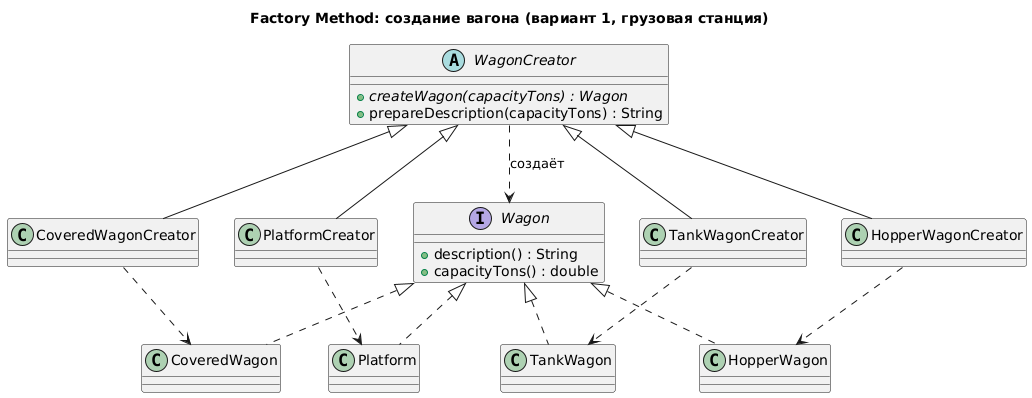

In [17]:
   !java -jar plantuml.jar -tpng factory.puml
   from IPython.display import Image
   Image("factory.png")

In [18]:
import os, subprocess

# Способ 1: скачать jar из Maven Central (этот сервер в Colab доступен)
JAR = "plantuml.jar"
URL = "https://repo1.maven.org/maven2/net/sourceforge/plantuml/plantuml/1.2024.7/plantuml-1.2024.7.jar"
if not os.path.exists(JAR) or os.path.getsize(JAR) < 1_000_000:
    print(subprocess.run(["wget", "-O", JAR, URL], capture_output=True, text=True).stderr[-300:])
print("jar скачан:", os.path.exists(JAR) and os.path.getsize(JAR) > 1_000_000)

def build(name):
    """Построить name.png из name.puml: сначала через jar, при неудаче через онлайн-сервис."""
    src, out = name + ".puml", name + ".png"
    if not os.path.exists(src):
        print(name, ": нет файла", src, "- сначала запустите ячейку %%writefile", src)
        return
    if os.path.exists(JAR):
        subprocess.run(["java", "-Dfile.encoding=UTF-8", "-jar", JAR, "-charset", "UTF-8", "-tpng", src],
                       capture_output=True, text=True)
    if not os.path.exists(out):
        # Способ 2: онлайн-сервис Kroki (установка не нужна)
        import requests
        ответ = requests.post("https://kroki.io/plantuml/png",
                              data=open(src, encoding="utf-8").read().encode("utf-8"),
                              headers={"Content-Type": "text/plain"}, timeout=60)
        if ответ.status_code == 200:
            open(out, "wb").write(ответ.content)
        else:
            print(name, ": Kroki вернул", ответ.status_code, ответ.text[:200])
    print(name, ":", "готово" if os.path.exists(out) else "НЕ ПОСТРОЕНА")

for имя in ("strategy", "factory", "observer"):
    build(имя)

jar скачан: True
strategy : готово
factory : готово
observer : готово


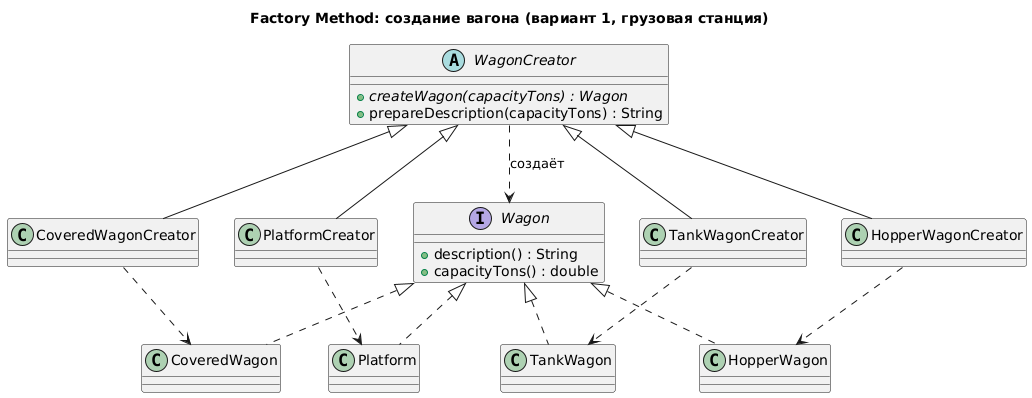

In [19]:
from IPython.display import Image
Image("factory.png")

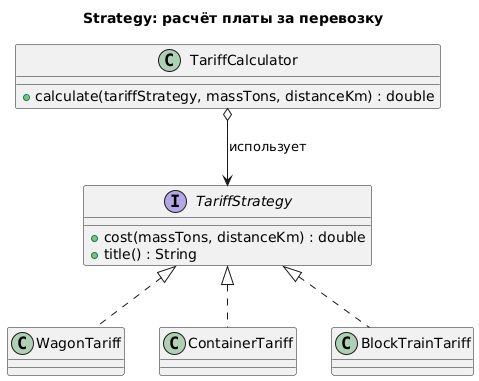

In [20]:
from IPython.display import Image
Image("strategy.png")

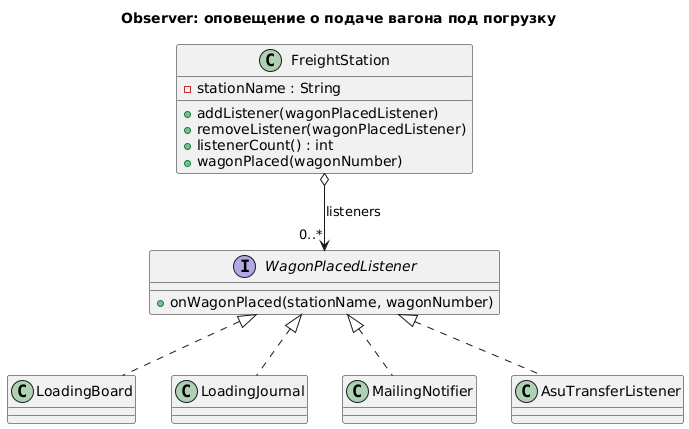

In [21]:
from IPython.display import Image
Image("observer.png")

In [22]:
import os
for имя in ("plantuml.jar", "strategy.puml", "factory.puml", "observer.puml",
            "strategy.png", "factory.png", "observer.png"):
    print(имя.ljust(15), "есть" if os.path.exists(имя) else "НЕТ")

plantuml.jar    есть
strategy.puml   есть
factory.puml    есть
observer.puml   есть
strategy.png    есть
factory.png     есть
observer.png    есть


observer.puml записан: True
Ответ Kroki: 200
observer.png построен: True


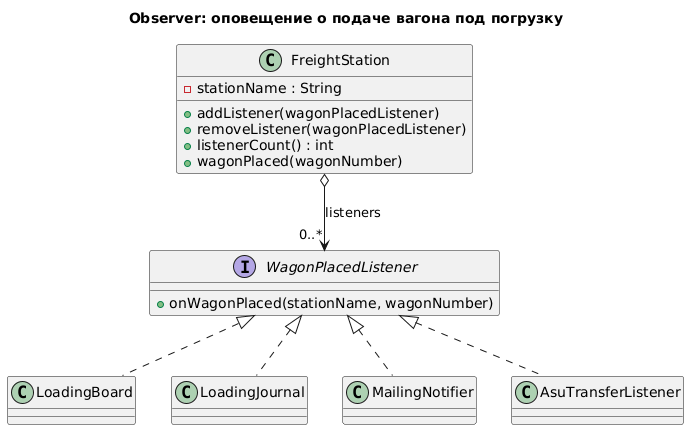

In [23]:
import os, subprocess, requests
from IPython.display import Image, display

# 1. Записать observer.puml
puml_text = """@startuml
title Observer: оповещение о подаче вагона под погрузку

interface WagonPlacedListener {
  +onWagonPlaced(stationName, wagonNumber)
}

class FreightStation {
  -stationName : String
  +addListener(wagonPlacedListener)
  +removeListener(wagonPlacedListener)
  +listenerCount() : int
  +wagonPlaced(wagonNumber)
}

class LoadingBoard
class LoadingJournal
class MailingNotifier
class AsuTransferListener

FreightStation o--> "0..*" WagonPlacedListener : listeners
WagonPlacedListener <|.. LoadingBoard
WagonPlacedListener <|.. LoadingJournal
WagonPlacedListener <|.. MailingNotifier
WagonPlacedListener <|.. AsuTransferListener
@enduml
"""
open("observer.puml", "w", encoding="utf-8").write(puml_text)
print("observer.puml записан:", os.path.exists("observer.puml"))

# 2. Построить observer.png через онлайн-сервис Kroki
ответ = requests.post("https://kroki.io/plantuml/png",
                      data=puml_text.encode("utf-8"),
                      headers={"Content-Type": "text/plain"}, timeout=60)
print("Ответ Kroki:", ответ.status_code)
if ответ.status_code == 200:
    open("observer.png", "wb").write(ответ.content)
else:
    print(ответ.text[:300])

print("observer.png построен:", os.path.exists("observer.png"))
if os.path.exists("observer.png"):
    display(Image("observer.png"))

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): Создание через new в вызывающем коде привязывает его к конкретным классам и требует выбора типа (if). Фабричный метод переносит выбор в подкласс создателя, а вызывающий код работает с Wagon и WagonCreator. Новый тип добавляется парой классов без правки старых. Фабрика излишня, когда тип один или заранее известен и не меняется, а объект создаётся просто. Тогда достаточно new, а лишние классы только усложняют код.

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [24]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Overwriting ObserverBefore.java


In [25]:
!java ObserverBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [26]:
%%writefile ObserverAfter.java
// Observer: оповещение о подаче вагона под погрузку.
// Вариант 1: грузовая станция, событие «вагон подан под погрузку».
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Общий список фиксирует порядок, в котором подписчики получили событие
        List<String> deliveryOrder = new ArrayList<>();

        FreightStation freightStation = new FreightStation("Гомель-Грузовой");
        LoadingBoard loadingBoard = new LoadingBoard(deliveryOrder);
        LoadingJournal loadingJournal = new LoadingJournal(deliveryOrder);
        MailingNotifier mailingNotifier = new MailingNotifier(deliveryOrder);

        freightStation.addListener(loadingBoard);
        freightStation.addListener(loadingJournal);
        freightStation.addListener(mailingNotifier);

        System.out.println("--- Событие 1: подписаны табло, журнал, рассылка ---");
        freightStation.wagonPlaced("52814370");
        System.out.println("Порядок получения события: " + deliveryOrder);

        check("после одного события журнал получил ровно одну запись",
                loadingJournal.journalEntries().size() == 1);
        check("все подписчики получили одно и то же событие",
                "52814370".equals(loadingBoard.lastWagonNumber())
                        && "52814370".equals(mailingNotifier.lastWagonNumber())
                        && loadingJournal.journalEntries().get(0).contains("52814370"));
        check("порядок получения совпадает с порядком подписки",
                deliveryOrder.equals(List.of("табло", "журнал", "рассылка")));

        System.out.println();
        System.out.println("--- Событие 2: рассылка отписана ---");
        freightStation.removeListener(mailingNotifier);
        freightStation.wagonPlaced("63027715");

        check("после отписки записи рассылки больше не появляются",
                mailingNotifier.receivedCount() == 1
                        && "52814370".equals(mailingNotifier.lastWagonNumber()));
        check("оставшиеся подписчики продолжают получать события",
                loadingJournal.journalEntries().size() == 2 && loadingBoard.receivedCount() == 2);

        System.out.println();
        System.out.println("--- Событие 3: добавлен четвёртый наблюдатель, FreightStation не менялась ---");
        AsuTransferListener asuTransferListener = new AsuTransferListener(deliveryOrder);
        freightStation.addListener(asuTransferListener);
        freightStation.wagonPlaced("58190246");

        check("четвёртый наблюдатель подключён без правки FreightStation и получил событие",
                asuTransferListener.receivedCount() == 1
                        && "58190246".equals(asuTransferListener.lastWagonNumber()));
        check("число подписчиков: табло, журнал, АСУ", freightStation.listenerCount() == 3);

        finishChecks();
    }

    // --- служебное ---

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    static void finishChecks() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }
}

// --- участники паттерна Observer ---

/** Наблюдатель: общий интерфейс получателей события. */
interface WagonPlacedListener {
    void onWagonPlaced(String stationName, String wagonNumber);
}

/** Субъект: хранит список наблюдателей и не знает, какие именно они бывают. */
class FreightStation {

    private final String stationName;
    private final List<WagonPlacedListener> listeners = new ArrayList<>();

    FreightStation(String stationName) {
        this.stationName = stationName;
    }

    void addListener(WagonPlacedListener wagonPlacedListener) {
        listeners.add(wagonPlacedListener);
    }

    void removeListener(WagonPlacedListener wagonPlacedListener) {
        listeners.remove(wagonPlacedListener);
    }

    int listenerCount() {
        return listeners.size();
    }

    void wagonPlaced(String wagonNumber) {
        for (int index = 0; index < listeners.size(); index++) {
            listeners.get(index).onWagonPlaced(stationName, wagonNumber);
        }
    }
}

class LoadingBoard implements WagonPlacedListener {
    private final List<String> deliveryOrder;
    private String lastWagonNumber;
    private int receivedCount = 0;

    LoadingBoard(List<String> deliveryOrder) {
        this.deliveryOrder = deliveryOrder;
    }

    public void onWagonPlaced(String stationName, String wagonNumber) {
        System.out.println("[табло]    Вагон " + wagonNumber + " подан под погрузку на станции " + stationName);
        deliveryOrder.add("табло");
        lastWagonNumber = wagonNumber;
        receivedCount++;
    }

    String lastWagonNumber() { return lastWagonNumber; }
    int receivedCount() { return receivedCount; }
}

/** Журнал накапливает записи, чтобы их можно было проверить. */
class LoadingJournal implements WagonPlacedListener {
    private final List<String> deliveryOrder;
    private final List<String> journalEntries = new ArrayList<>();

    LoadingJournal(List<String> deliveryOrder) {
        this.deliveryOrder = deliveryOrder;
    }

    public void onWagonPlaced(String stationName, String wagonNumber) {
        String journalEntry = stationName + ": вагон " + wagonNumber + " подан под погрузку";
        System.out.println("[журнал]   " + journalEntry);
        deliveryOrder.add("журнал");
        journalEntries.add(journalEntry);
    }

    List<String> journalEntries() { return journalEntries; }
}

class MailingNotifier implements WagonPlacedListener {
    private final List<String> deliveryOrder;
    private String lastWagonNumber;
    private int receivedCount = 0;

    MailingNotifier(List<String> deliveryOrder) {
        this.deliveryOrder = deliveryOrder;
    }

    public void onWagonPlaced(String stationName, String wagonNumber) {
        System.out.println("[рассылка] Грузоотправителю: вагон " + wagonNumber + " подан на станции " + stationName);
        deliveryOrder.add("рассылка");
        lastWagonNumber = wagonNumber;
        receivedCount++;
    }

    String lastWagonNumber() { return lastWagonNumber; }
    int receivedCount() { return receivedCount; }
}

// --- четвёртый наблюдатель: добавлен новым классом, FreightStation не менялась ---

class AsuTransferListener implements WagonPlacedListener {
    private final List<String> deliveryOrder;
    private String lastWagonNumber;
    private int receivedCount = 0;

    AsuTransferListener(List<String> deliveryOrder) {
        this.deliveryOrder = deliveryOrder;
    }

    public void onWagonPlaced(String stationName, String wagonNumber) {
        System.out.println("[АСУ]      Передано в АСУ: вагон " + wagonNumber + ", станция " + stationName);
        deliveryOrder.add("АСУ");
        lastWagonNumber = wagonNumber;
        receivedCount++;
    }

    String lastWagonNumber() { return lastWagonNumber; }
    int receivedCount() { return receivedCount; }
}

Overwriting ObserverAfter.java


In [27]:
!java ObserverAfter.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Событие 1: подписаны табло, журнал, рассылка ---
[табло]    Вагон 52814370 подан под погрузку на станции Гомель-Грузовой
[журнал]   Гомель-Грузовой: вагон 52814370 подан под погрузку
[рассылка] Грузоотправителю: вагон 52814370 подан на станции Гомель-Грузовой
Порядок получения события: [табло, журнал, рассылка]
[OK]   после одного события журнал получил ровно одну запись
[OK]   все подписчики получили одно и то же событие
[OK]   порядок получения совпадает с порядком подписки

--- Событие 2: рассылка отписана ---
[табло]    Вагон 63027715 подан под погрузку на станции Гомель-Грузовой
[журнал]   Гомель-Грузовой: вагон 63027715 подан под погрузку
[OK]   после о

In [28]:
%%writefile observer.puml
@startuml
title Observer: оповещение о подаче вагона под погрузку

interface WagonPlacedListener {
  +onWagonPlaced(stationName, wagonNumber)
}

class FreightStation {
  -stationName : String
  +addListener(wagonPlacedListener)
  +removeListener(wagonPlacedListener)
  +listenerCount() : int
  +wagonPlaced(wagonNumber)
}

class LoadingBoard
class LoadingJournal
class MailingNotifier
class AsuTransferListener

FreightStation o--> "0..*" WagonPlacedListener : listeners
WagonPlacedListener <|.. LoadingBoard
WagonPlacedListener <|.. LoadingJournal
WagonPlacedListener <|.. MailingNotifier
WagonPlacedListener <|.. AsuTransferListener
@enduml

Overwriting observer.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


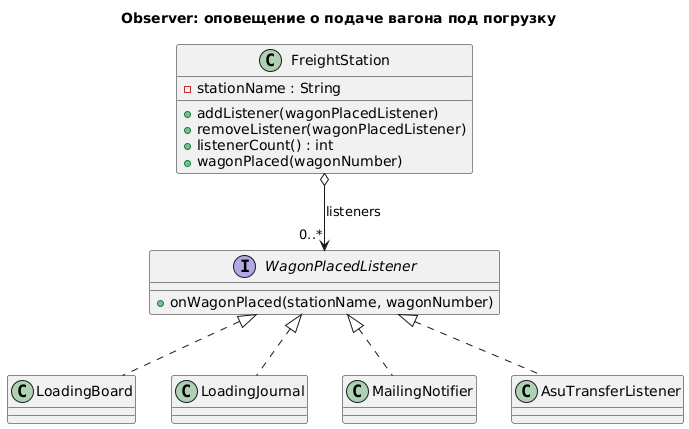

In [29]:
   !java -jar plantuml.jar -tpng observer.puml
   from IPython.display import Image
   Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка): Observer снял связанность станции с конкретными получателями: FreightStation знает только интерфейс WagonPlacedListener, а новые получатели подключаются без правки станции. Появились новые проблемы:
Порядок уведомлений. Он определяется порядком подписки, и на него нельзя полагаться неявно.
Ошибка в одном подписчике. Исключение может прервать оповещение остальных.
Забытая отписка. Станция держит ссылку на подписчика, и он не освобождается из памяти.
Изменение списка во время обхода. Отписка внутри обработчика сбивает индексы.

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy | Условный оператор по виду отправки в одном методе, нарушение OCP и SRP | Новый вид расчёта платы (новый класс стратегии) | Больше классов, нужен каталог или выбор стратегии | Расчёт платы за пользование вагонами |
| Factory Method | Создание и описание объекта через разбор строкового типа | Новый тип вагона (продукт и создатель) | Параллельная иерархия продуктов и создателей | Создание вагонов разных типов |
| Observer | Источник события жёстко знает всех получателей | Новый получатель события (новый наблюдатель) | Неявный порядок уведомлений, риск утечек и ошибок в подписчиках | Оповещение о подаче вагона под погрузку |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** Разбор типа условным оператором нарушает принцип открытости/закрытости: для нового варианта правится рабочий код. Strategy выносит варианты расчёта в классы с общим интерфейсом. Factory Method выносит создание типа в подклассы создателя. Observer выносит получателей из источника события в подписчиков. Во всех трёх случаях расширение идёт новым классом.
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** Статический фабричный метод — это просто метод, возвращающий объект. Он не образует иерархию, и его нельзя переопределить подклассом. Factory Method опирается на наследование: подкласс создателя решает, какой продукт создать. Abstract Factory создаёт целое семейство связанных продуктов, а Factory Method — один продукт.
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** Структура классов почти одинакова, различается назначение. Strategy взаимозаменяет алгоритм, выбор делает клиент, и стратегии обычно не знают друг о друге. State меняет поведение объекта при смене его внутреннего состояния, переходы между состояниями выполняют сами состояния или контекст.
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** Субъект хранит ссылки на подписчиков, поэтому забытый подписчик не освобождается сборщиком мусора, даже если больше не нужен. Решение: всегда вызывать removeListener, использовать слабые ссылки (WeakReference) или ограничивать время жизни подписки.
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** Паттерн вреден, когда вариантов нет и не предвидится. Например, Strategy для единственной формулы или фабрика для одного класса. Преждевременное усложнение — это введение абстракций «на будущее» без реальной потребности: код разрастается, а выгоды нет.

### 5.3 Три вывода по работе в целом

1. Паттерн оправдан, когда ожидается рост числа вариантов: тогда расширение идёт новыми классами без правки рабочего кода
2. Характеризующие тесты (legacyCost, [OK]/[FAIL]) позволяют переписывать код безопасно и доказывать, что поведение не изменилось.
3. У каждого паттерна своя цена (больше классов, неочевидный порядок уведомлений), поэтому применять его нужно под конкретную проблему, а не по умолчанию.

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [31]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Матюшков Денис Владимирович"  #@param {type:"string"}
Группа_исполнителя = "ГИ-41"  #@param {type:"string"}
Номер_варианта = 1  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Матюшков Денис Владимирович, группа ГИ-41, вариант 1 |
| Дата и время отчёта (UTC) | 2026-11-13 19:16 |
| Версия Java | openjdk version "21.0.13.0.3" 2026-10-24 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 10 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 7 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |